# Chapter 45A — From model performance to statistical product validity
Public reference: scikit-learn bundled Wisconsin Diagnostic Breast Cancer dataset (https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html; UCI source https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic). This is a teaching benchmark, not a representative population or clinical tool. Target: malignant-label fraction in a fixed held-out reference set. Sampling, corruption and missingness are simulated. No external services. Requirements: numpy, pandas, scipy, scikit-learn, matplotlib. Three workflows share samples; C uses bounded deterministic orchestration, not a live LLM. Labels are used only for training, calibration and retrospective evaluation, never production review. Intervals use independent calibration bootstrap and sample bootstrap; coverage is empirical for this simulation.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
rng=np.random.default_rng(45)
X,y=load_breast_cancer(return_X_y=True); y=1-y
tr,rest=train_test_split(np.arange(len(y)),test_size=.6,stratify=y,random_state=45)
cal,pop=train_test_split(rest,test_size=.5,stratify=y[rest],random_state=46)
model=make_pipeline(SimpleImputer(),StandardScaler(),LogisticRegression(max_iter=2000)).fit(X[tr],y[tr])
cut=np.median(X[tr,0]); target=y[pop].mean()
print('Reference population',len(pop),'target',target)

Reference population 171 target 0.3742690058479532


In [2]:
def corrupt(ids,r):
    z=X[ids].copy(); shock=r.normal(0,.6,len(ids))
    z[:,0]+=shock; z[:,2]+=5*shock
    z[r.random(z.shape)<.03]=np.nan
    return z

def predict(z,kind):
    if kind=='A': return (np.nan_to_num(z[:,0],nan=cut)>cut).astype(int),0
    prob=model.predict_proba(z)[:,1]; pred=(prob>=.5).astype(int)
    review=(abs(prob-.5)<.15)|np.isnan(z).any(axis=1)
    if kind=='C':
        # Approved fallback uses available radius only, not hidden truth.
        fallback=review & np.isfinite(z[:,0]) & (abs(prob-.5)<.15)
        pred[fallback]=(z[fallback,0]>cut).astype(int)
    return pred, int(review.sum()) if kind=='C' else 0

def rates(a,b):
    tn,fp,fn,tp=confusion_matrix(a,b,labels=[0,1]).ravel()
    return (tp+.5)/(tp+fn+1),(tn+.5)/(tn+fp+1)

def correct(q,se,sp):
    den=se+sp-1
    return (q+sp-1)/den if den>.15 else np.nan


          bias     mse  coverage  ...   review  seconds  release_rate
system                            ...                                
A       0.1329  0.0202    0.2467  ...   0.0000   0.0421          0.46
B       0.0047  0.0024    0.9400  ...   0.0000   0.0434          1.00
C      -0.0129  0.0027    0.9333  ...  61.7467   0.0432          1.00

[3 rows x 9 columns]
Conditional released bias: system
A    0.136021
B    0.004734
C   -0.012920
Name: bias, dtype: float64


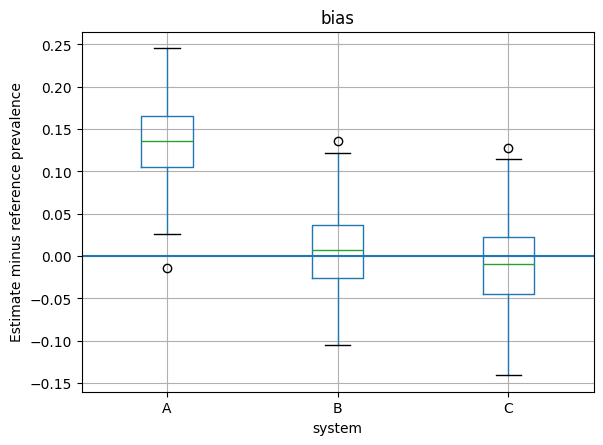

In [3]:
rows=[]
for rep in range(150):
    ids=rng.choice(pop,100,replace=True); z=corrupt(ids,rng); zc=corrupt(cal,rng)
    # subgroup defined by a fixed training-derived radius threshold, for illustration
    group=X[ids,0]>cut
    for kind in ['A','B','C']:
        start=time.perf_counter(); pred,review=predict(z,kind); pc,_=predict(zc,kind)
        se,sp=rates(y[cal],pc); est=pred.mean() if kind=='A' else correct(pred.mean(),se,sp)
        draws=[]
        for _ in range(100):
            i=rng.integers(len(ids),size=len(ids)); j=rng.integers(len(cal),size=len(cal))
            s,t=rates(y[cal][j],pc[j]); q=pred[i].mean()
            draws.append(q if kind=='A' else correct(q,s,t))
        finite=np.asarray(draws)[np.isfinite(draws)]
        lo,hi=np.quantile(finite,[.025,.975]) if len(finite)>=95 else (np.nan,np.nan)
        # Gate uses calibration labels, never production labels or true target.
        errors=[np.mean(pc[g]!=y[cal][g]) for g in [X[cal,0]<=cut,X[cal,0]>cut] if g.any()]
        release=bool(np.isfinite(est) and 0<=est<=1 and np.isfinite(lo) and max(errors)<=.35 and hi-lo<=.45)
        rows.append(dict(rep=rep,system=kind,estimate=est,bias=est-target,sq_error=(est-target)**2,covered=(lo<=target<=hi),interval_valid=np.isfinite(lo),subgroup_error_low=np.mean(pred[~group]!=y[ids][~group]),subgroup_error_high=np.mean(pred[group]!=y[ids][group]),review=review,seconds=time.perf_counter()-start,released=release))
r=pd.DataFrame(rows)
summary=r.groupby('system').agg(bias=('bias','mean'),mse=('sq_error','mean'),coverage=('covered','mean'),valid_intervals=('interval_valid','mean'),low_error=('subgroup_error_low','mean'),high_error=('subgroup_error_high','mean'),review=('review','mean'),seconds=('seconds','mean'),release_rate=('released','mean'))
print(summary.round(4)); print('Conditional released bias:',r[r.released].groupby('system').bias.mean())
assert len(r)==450 and r.groupby('rep').size().eq(3).all()
r.boxplot(column='bias',by='system'); plt.axhline(0); plt.ylabel('Estimate minus reference prevalence'); plt.suptitle(''); plt.show()

## Interpretation and limitations
Coverage counts invalid intervals as failures; bias/MSE exclude nonfinite estimates, so inspect valid interval and release rates. Timing includes bootstrap evaluation and is hardware dependent. A is uncorrected, B and C corrected: differences combine classification and estimation choices. To isolate the correction effect, rerun all three with identical correction. C review is a flag count, not human labour measured in practice. The gate is applied to all systems for comparability. No confidentiality or real release authority is simulated beyond this numerical gate. Explore sensitivity to corruption, subgroup definition, calibration size and thresholds. Do not infer clinical prevalence or causal effects.